# DATA CLEANING

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [10]:
df=pd.read_csv('ridge_regression.csv')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   feature_1     1000 non-null   float64
 1   feature_2_mc  1000 non-null   float64
 2   feature_3_mc  1000 non-null   float64
 3   feature_4     1000 non-null   float64
 4   feature_5     1000 non-null   float64
 5   feature_6_mc  1000 non-null   float64
 6   feature_7     1000 non-null   float64
 7   feature_8     1000 non-null   float64
 8   noise_1       1000 non-null   float64
 9   noise_2       1000 non-null   float64
 10  noise_3       1000 non-null   float64
 11  noise_4       1000 non-null   float64
 12  noise_5       1000 non-null   float64
 13  noise_6       1000 non-null   float64
 14  noise_7       1000 non-null   float64
 15  noise_8       1000 non-null   float64
 16  noise_9       1000 non-null   float64
 17  noise_10      1000 non-null   float64
 18  target        1000 non-null  

In [16]:
df.isnull().sum()

feature_1       0
feature_2_mc    0
feature_3_mc    0
feature_4       0
feature_5       0
feature_6_mc    0
feature_7       0
feature_8       0
noise_1         0
noise_2         0
noise_3         0
noise_4         0
noise_5         0
noise_6         0
noise_7         0
noise_8         0
noise_9         0
noise_10        0
target          0
dtype: int64

In [12]:
df.describe()

,feature_1,feature_2_mc,feature_3_mc,feature_4,feature_5,feature_6_mc,feature_7,feature_8,noise_1,noise_2,noise_3,noise_4,noise_5,noise_6,noise_7,noise_8,noise_9,noise_10,target
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,55.877428,111.724878,61.396318,24.762379,301.629395,37.200431,0.269567,0.501323,-0.001843,0.011812,-0.006768,-0.030593,0.021752,-0.022160,-0.003164,0.011103,-0.022986,0.033537,134.731532
std,26.045613,52.176803,28.742125,14.295666,117.553525,21.670784,11.541938,0.289343,0.986241,1.016608,0.980147,0.993824,0.986796,0.954517,1.001982,0.981457,1.018548,0.998341,87.646021
min,10.131584,17.925736,8.879100,0.009217,101.146442,-6.054849,-19.948754,0.001678,-3.043403,-3.000637,-3.331354,-3.330694,-2.973270,-2.822217,-2.980414,-3.351725,-3.120927,-3.534826,-84.916853
25%,34.205840,67.500233,37.437138,12.892174,197.181321,19.294973,-10.063501,0.247844,-0.691681,-0.689028,-0.623580,-0.708279,-0.664205,-0.725717,-0.698298,-0.592200,-0.687885,-0.656159,63.292901
50%,57.631922,115.362989,63.253541,24.296902,305.411795,36.580163,0.473340,0.503187,-0.005111,-0.007839,-0.041163,-0.021693,0.056659,-0.018325,0.010650,0.023062,-0.004786,0.028390,137.443170
75%,77.874406,155.101923,85.637374,36.646095,402.537419,55.806480,10.250930,0.752140,0.640627,0.692760,0.611312,0.644062,0.701034,0.665070,0.600816,0.634316,0.664472,0.734914,205.959078
max,99.885536,201.818048,110.722534,49.978621,499.417917,81.048529,19.996313,0.999282,3.588850,3.646272,2.931068,3.288771,3.449000,3.169629,3.089478,3.062199,2.845481,3.098311,338.687978


<Axes: >

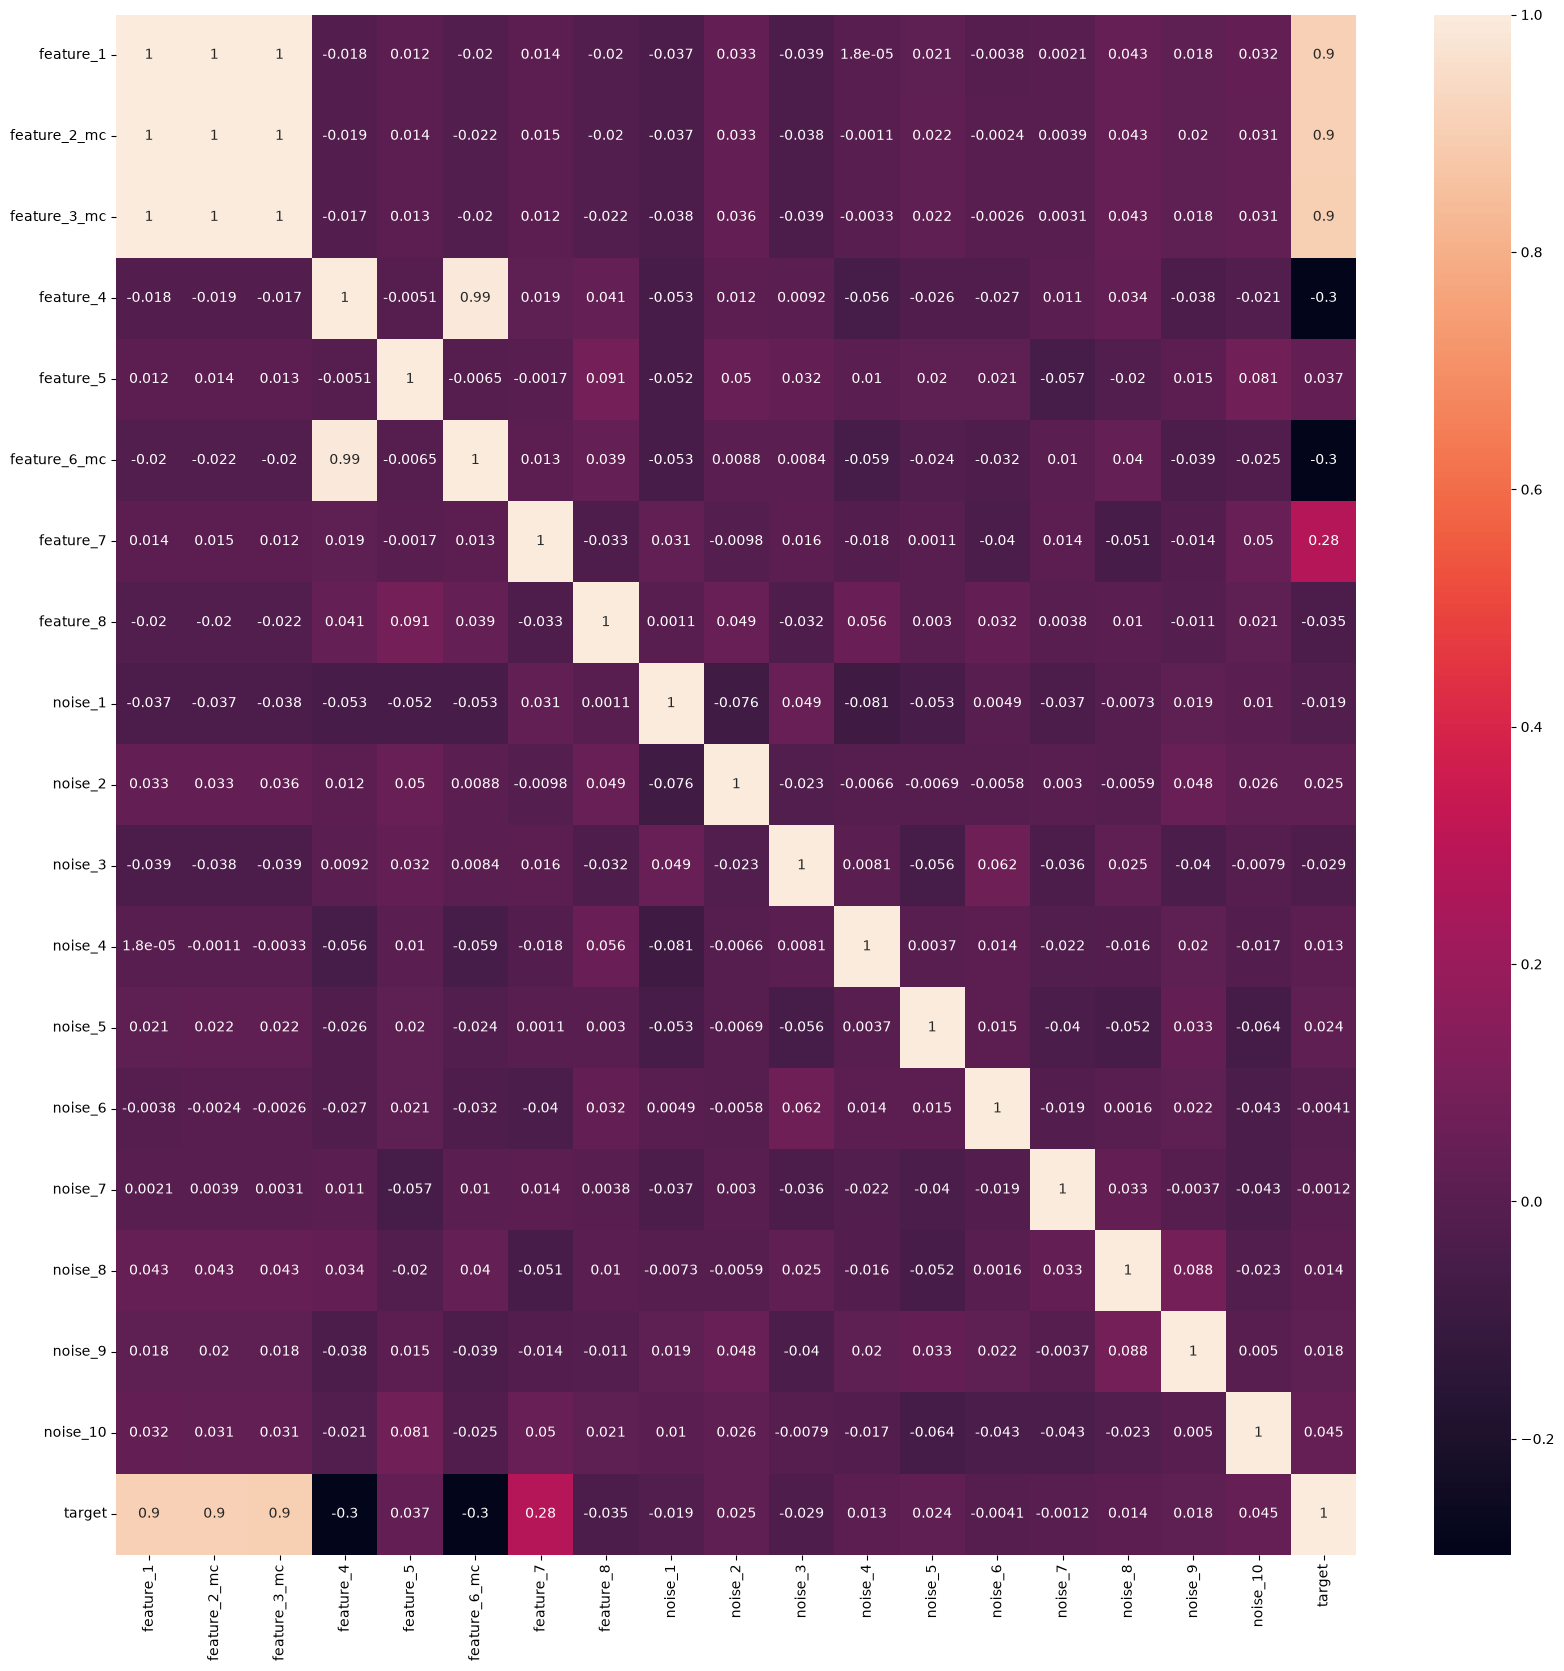

In [20]:
plt.figure(figsize=(20,20))

sns.heatmap(df.corr(),annot=True)

## Model training

In [13]:
X=df.drop("target",axis=1)
y=df["target"]

In [14]:
from sklearn.model_selection import train_test_split

X_test,X_train,y_test,y_train=train_test_split(X,y,random_state=42,test_size=0.2)

#### Model 1: Linear Regression

In [23]:
from sklearn.linear_model import LinearRegression

LR=LinearRegression()

model=LR.fit(X_train,y_train)

y_pred=model.predict(X_test)




In [24]:
# Evaluation 

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)


print("MAE: ",mae)
print("MSE: ",mse)
print("R2:  ",r2)



MAE:  12.625712720881257
MSE:  253.64687383990727
R2:   0.9665220096765872


#### Model 2: Ridge

In [25]:
from sklearn.linear_model import Ridge

# crete the instance
model=Ridge(alpha=1)

# model
model.fit(X_train,y_train)

y_pred=model.predict(X_test)



In [26]:
# Evaluation 

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)


print("MAE: ",mae)
print("MSE: ",mse)
print("R2:  ",r2)

MAE:  12.619166987343647
MSE:  253.43173317603305
R2:   0.9665504053628983


#### Model 3: Lasso

In [27]:
from sklearn.linear_model import Lasso

lass=Lasso()

lass.fit(X_train,y_train)

y_pred=lass.predict(X_test)

c:\Users\vaish\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.870e+02, tolerance: 1.602e+02
  model = cd_fast.enet_coordinate_descent(


In [28]:
# Evaluation 

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)


print("MAE: ",mae)
print("MSE: ",mse)
print("R2:  ",r2)

MAE:  12.36747601587851
MSE:  243.13601269132852
R2:   0.9679093025791008
